In [5]:
import pandas as pd
df=pd.read_csv(r'C:\Users\anugr\OneDrive\Documents\Desktop\ML project\CORRECTED_2023_2026_NEPAL_FLOOD_WEATHER_KAGGLE.csv')

In [6]:
df.isna().sum()

date                           0
location                       0
river                          0
basin                          0
dhm_station                    0
latitude                       0
longitude                      0
elevation_m                    0
precipitation_mm               0
soil_moisture_0_100cm_m3m3     0
rain_mm                        0
temperature_mean_c             0
dew_point_mean_c               0
precipitation_hours            0
relative_humidity_mean_pct     0
wind_speed_max_kmh             0
wind_gusts_max_kmh             0
wind_direction_dominant_deg    0
river_discharge_m3s            0
dtype: int64

In [7]:
import matplotlib.pyplot as plt

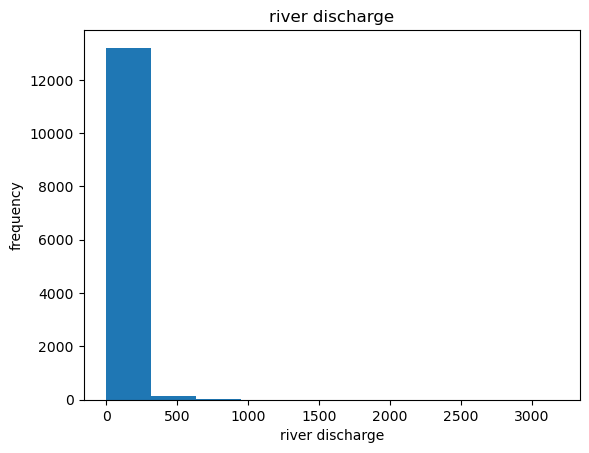

In [8]:
plt.hist(df['river_discharge_m3s'])
plt.ylabel('frequency')
plt.xlabel('river discharge')
plt.title('river discharge')
plt.show()

In [9]:
#Identify the river station/location with the highest average river discharge
df.groupby('location')['river_discharge_m3s'].mean().sort_values(ascending=False)

location
Kusum                  125.812158
Belsot                  33.032636
Chameliya/Nayalbadi     31.393465
Bahrabise                5.051314
Devghat                  2.331277
Khokana                  1.658006
Chatara                  1.491344
Rasuwagadhi              1.406751
Chisapani                0.847072
Bhada Bridge             0.696617
Name: river_discharge_m3s, dtype: float64

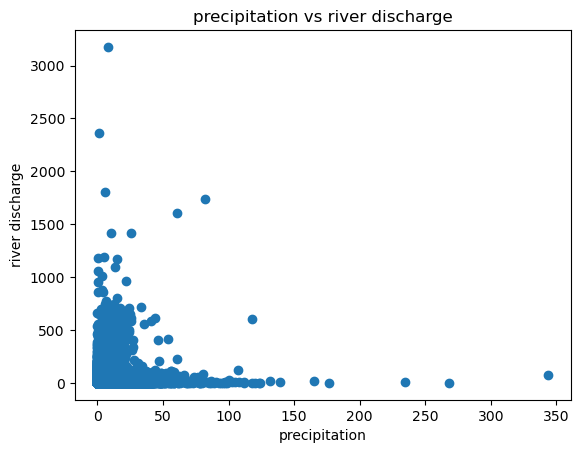

In [10]:
#Analyze the relationship between rainfall/precipitation and river discharge
plt.scatter(df['precipitation_mm'],df['river_discharge_m3s'])
plt.xlabel('precipitation')
plt.ylabel('river discharge')
plt.title('precipitation vs river discharge')
plt.show()

In [11]:
#Identify which weather variable has the strongest relationship with river discharge.
corr=df.corr(numeric_only=True)
dcorr=corr['river_discharge_m3s'].drop('river_discharge_m3s')
dcorr

dhm_station                   -0.085259
latitude                       0.031714
longitude                     -0.131079
elevation_m                   -0.175532
precipitation_mm               0.098626
soil_moisture_0_100cm_m3m3     0.151942
rain_mm                        0.099743
temperature_mean_c             0.178499
dew_point_mean_c               0.226308
precipitation_hours            0.145097
relative_humidity_mean_pct     0.171687
wind_speed_max_kmh             0.051560
wind_gusts_max_kmh            -0.009484
wind_direction_dominant_deg   -0.040901
Name: river_discharge_m3s, dtype: float64

In [12]:
dcorr.abs().idxmax()

'dew_point_mean_c'

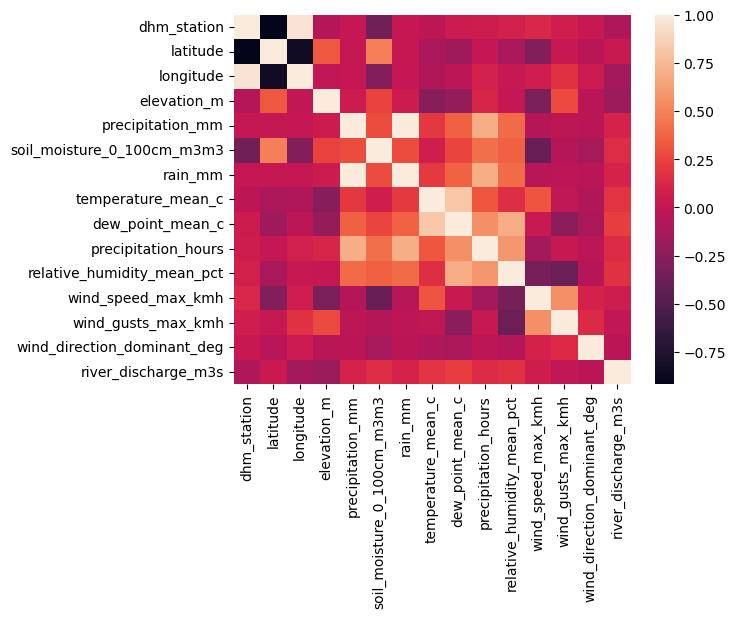

In [13]:
import seaborn as sns
sns.heatmap(corr)
plt.show()

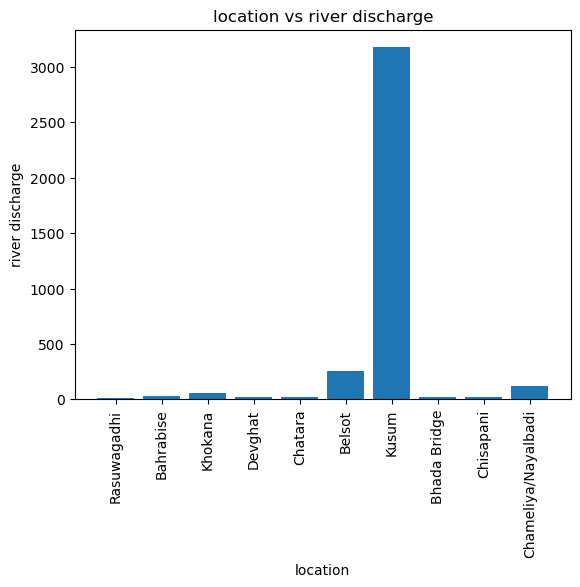

In [14]:
#Compare river discharge across different river stations/locations.
plt.bar(df['location'],df['river_discharge_m3s'])
plt.xlabel('location')
plt.ylabel('river discharge')
plt.title('location vs river discharge')
plt.xticks(rotation=90)
plt.show()

In [15]:
#Analyze the monthly or seasonal pattern of river discharge
df['date']=pd.to_datetime(df['date'], dayfirst=True, errors='coerce')
df['month']=df['date'].dt.month
n=df.groupby('month')['river_discharge_m3s'].mean()
n

month
1.0     20.137273
2.0     17.760932
3.0     17.490636
4.0     21.054545
5.0     22.036636
6.0     22.820909
7.0     23.567682
8.0     22.585909
9.0     21.765000
10.0    19.854205
11.0    19.701545
12.0    19.014773
Name: river_discharge_m3s, dtype: float64

Text(0.5, 1.0, 'month vs river discharge')

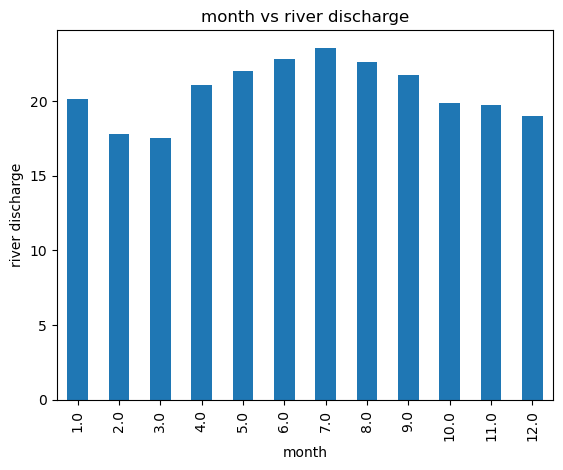

In [16]:
n.plot(kind='bar')
plt.xlabel('month')
plt.ylabel('river discharge')
plt.title('month vs river discharge')

In [17]:
#Identify periods with unusually high river discharge.(IQR)
q1=df['river_discharge_m3s'].quantile(0.25)
q3=df['river_discharge_m3s'].quantile(0.75)
iqr=q3-q1
#lower=q1-1.5*iqr
upper=q3+1.5*iqr
outliers=df[df['river_discharge_m3s']>upper]
outliers



,date,location,river,basin,dhm_station,latitude,longitude,elevation_m,precipitation_mm,soil_moisture_0_100cm_m3m3,rain_mm,temperature_mean_c,dew_point_mean_c,precipitation_hours,relative_humidity_mean_pct,wind_speed_max_kmh,wind_gusts_max_kmh,wind_direction_dominant_deg,river_discharge_m3s,month
590,NaT,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,0.1,0.421,0.1,25.2,21.0,1,79,6.0,20.9,164,28.04,NaN
602,NaT,Bahrabise,Bhote Koshi,Koshi,610.0,27.786773,85.899324,1870,14.7,0.426,14.7,23.7,21.6,9,88,4.7,19.4,203,26.54,NaN
2020,NaT,Belsot,Kamala,Kamala,595.5,26.912863,86.248330,188,4.5,0.362,4.5,28.9,25.4,6,82,13.7,29.5,114,28.24,NaN
2021,NaT,Belsot,Kamala,Kamala,595.5,26.912863,86.248330,188,0.6,0.358,0.6,29.5,24.6,2,75,19.0,38.9,115,27.84,NaN
2022,NaT,Belsot,Kamala,Kamala,595.5,26.912863,86.248330,188,0.4,0.352,0.4,29.0,24.3,3,76,23.8,47.5,117,27.44,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13373,NaT,Chameliya/Nayalbadi,Chamelia,Mahakali,120.0,29.674420,80.562680,685,12.6,0.492,12.6,26.0,24.8,20,93,5.3,20.5,259,70.45,NaN
13378,NaT,Kusum,West Rapti,Rapti,375.0,28.007500,82.093889,230,7.8,0.414,7.8,27.8,27.1,13,96,5.2,21.2,339,655.15,NaN
13381,NaT,Belsot,Kamala,Kamala,595.5,26.912863,86.248330,188,2.7,0.294,2.7,29.3,25.7,10,82,15.6,35.3,105,72.11,NaN
13383,NaT,Chameliya/Nayalbadi,Chamelia,Mahakali,120.0,29.674420,80.562680,685,22.8,0.497,22.8,26.5,24.5,23,90,6.3,23.8,323,71.28,NaN


In [18]:
#Create lag features for rainfall, such as previous-day, previous 2-day, and previous 3day rainfall.
df['raninfall_lag1']=df['rain_mm'].shift(1)
df['raninfall_lag2']=df['rain_mm'].shift(2)
df['raninfall_lag3']=df['rain_mm'].shift(3)
df[['date','rain_mm','raninfall_lag1','raninfall_lag2','raninfall_lag3']].head(10)

,date,rain_mm,raninfall_lag1,raninfall_lag2,raninfall_lag3
0,2023-01-01,0.0,NaN,NaN,NaN
1,2023-02-01,0.0,0.0,NaN,NaN
2,2023-03-01,0.0,0.0,0.0,NaN
3,2023-04-01,0.0,0.0,0.0,0.0
4,2023-05-01,0.0,0.0,0.0,0.0
5,2023-06-01,0.0,0.0,0.0,0.0
6,2023-07-01,0.0,0.0,0.0,0.0
7,2023-08-01,0.0,0.0,0.0,0.0
8,2023-09-01,0.0,0.0,0.0,0.0
9,2023-10-01,0.0,0.0,0.0,0.0


In [19]:
# Create rolling rainfall features such as 3-day and 7-day rainfall totals/averages.
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')

# 3-day rolling rainfall total and average
df['rain_3day_total'] = df['rain_mm'].rolling(window=3).sum()   #just sum cause sum of entire column we need 3 then 3 then3...
df['rain_3day_avg'] = df['rain_mm'].rolling(window=3).mean()

# 7-day rolling rainfall total and average
df['rain_7day_total'] = df['rain_mm'].rolling(window=7).sum()
df['rain_7day_avg'] = df['rain_mm'].rolling(window=7).mean()

# Display the results
df[['date', 'rain_mm', 'rain_3day_total',
    'rain_3day_avg', 'rain_7day_total',
    'rain_7day_avg']].head(10)

,date,rain_mm,rain_3day_total,rain_3day_avg,rain_7day_total,rain_7day_avg
0,2023-01-01,0.0,NaN,NaN,NaN,NaN
1095,2023-01-01,0.0,NaN,NaN,NaN,NaN
2190,2023-01-01,0.0,0.0,0.0,NaN,NaN
2555,2023-01-01,0.0,0.0,0.0,NaN,NaN
1460,2023-01-01,0.3,0.3,0.1,NaN,NaN
2920,2023-01-01,0.0,0.3,0.1,NaN,NaN
3285,2023-01-01,0.0,0.3,0.1,0.3,0.042857
730,2023-01-01,0.0,0.0,0.0,0.3,0.042857
365,2023-01-01,0.0,0.0,0.0,0.3,0.042857
1825,2023-01-01,0.0,0.0,0.0,0.3,0.042857


In [20]:
# Create previous-day river discharge feature
df['discharge_lag1'] = df['river_discharge_m3s'].shift(1)

# Display the result
df[['date', 'river_discharge_m3s', 'discharge_lag1']].head(10)

,date,river_discharge_m3s,discharge_lag1
0,2023-01-01,0.22,NaN
1095,2023-01-01,0.91,0.22
2190,2023-01-01,22.39,0.91
2555,2023-01-01,0.31,22.39
1460,2023-01-01,0.26,0.31
2920,2023-01-01,0.31,0.26
3285,2023-01-01,19.28,0.31
730,2023-01-01,0.01,19.28
365,2023-01-01,1.05,0.01
1825,2023-01-01,12.09,1.05


In [21]:
# Extract date features
df['year'] = df['date'].dt.year
df[['month','year']]

,month,year
0,1.0,2023.0
1095,1.0,2023.0
2190,1.0,2023.0
2555,1.0,2023.0
1460,1.0,2023.0
...,...,...
13385,NaN,NaN
13386,NaN,NaN
13387,NaN,NaN
13388,NaN,NaN
